<a href="https://colab.research.google.com/github/SarveeshK/HCL/blob/main/Unit-2/LSTM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Install Hugging Face datasets (to download the data) and keras-tuner (for auto hyperparameter tuning)
!pip install -q datasets keras-tuner

In [2]:
# Import basic data handling and visualization libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Import TensorFlow, Hugging Face dataset loader, and Scikit-Learn metrics
import tensorflow as tf
from datasets import load_dataset
from sklearn.metrics import confusion_matrix, classification_report

# Import text preprocessing and one-hot encoding tools
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.utils import to_categorical

# Import LSTM layers, pooling layers, and KerasTuner
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, Embedding, LSTM, Dense, Dropout, SpatialDropout1D,
    Bidirectional, GlobalMaxPooling1D, GlobalAveragePooling1D, Concatenate, BatchNormalization
)
import keras_tuner as kt

# Set random seed so we get the exact same high accuracy every time we run it
tf.random.set_seed(42)
np.random.seed(42)
print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.21.0


In [3]:
import numpy as np
from datasets import load_dataset

# Download the multiclass sentiment dataset directly from Hugging Face
print("Downloading Sp1786/multiclass-sentiment-analysis-dataset...")
dataset = load_dataset("Sp1786/multiclass-sentiment-analysis-dataset")

# Extract training text (convert to lowercase and remove extra spaces) and labels (0=Neg, 1=Neu, 2=Pos)
train_texts = [str(t).strip().lower() for t in dataset['train']['text']]
y_train = np.array(dataset['train']['label'])

# Extract validation text and labels (used to check accuracy during tuning)
val_texts = [str(t).strip().lower() for t in dataset['validation']['text']]
y_val = np.array(dataset['validation']['label'])

# Extract unseen testing text and labels (used for final accuracy check)
test_texts = [str(t).strip().lower() for t in dataset['test']['text']]
y_test = np.array(dataset['test']['label'])

# Print total number of rows in each split
print(f"Train samples      : {len(train_texts)}")
print(f"Validation samples : {len(val_texts)}")
print(f"Test samples       : {len(test_texts)}")

README.md:   0%|          | 0.00/1.72k [00:00<?, ?B/s]

train_df.csv:   0%|          | 0.00/3.56M [00:00<?, ?B/s]

val_df.csv:   0%|          | 0.00/601k [00:00<?, ?B/s]

test_df.csv:   0%|          | 0.00/586k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/31232 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/5205 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5206 [00:00<?, ? examples/s]

Train samples      : 31232
Validation samples : 5205
Test samples       : 5206


In [4]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.utils import to_categorical

# Keep top 20,000 most common words and fix sentence length to 100 words for LSTM
VOCAB_SIZE = 20000
MAX_LEN = 100

# Create a dictionary that gives a unique number ID to each word
tokenizer = Tokenizer(num_words=VOCAB_SIZE, oov_token="<OOV>")
tokenizer.fit_on_texts(train_texts)

# Convert text sentences into number lists, and pad with zeros so all sentences have length 100
X_train = pad_sequences(tokenizer.texts_to_sequences(train_texts), maxlen=MAX_LEN, padding='post', truncating='post')
X_val = pad_sequences(tokenizer.texts_to_sequences(val_texts), maxlen=MAX_LEN, padding='post', truncating='post')
X_test = pad_sequences(tokenizer.texts_to_sequences(test_texts), maxlen=MAX_LEN, padding='post', truncating='post')

# One-hot encode the 3 sentiment classes (0, 1, 2)
y_train_oh = to_categorical(y_train, num_classes=3)
y_val_oh = to_categorical(y_val, num_classes=3)
y_test_oh = to_categorical(y_test, num_classes=3)

# Check the final matrix shape (rows, 100)
print("X_train shape:", X_train.shape)
print("X_val shape  :", X_val.shape)
print("X_test shape :", X_test.shape)

X_train shape: (31232, 100)
X_val shape  : (5205, 100)
X_test shape : (5206, 100)


In [5]:
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, Embedding, LSTM, Dense, Dropout, SpatialDropout1D,
    Bidirectional, GlobalMaxPooling1D, GlobalAveragePooling1D, Concatenate, BatchNormalization
)
import keras_tuner as kt

# Custom Model class implementing explicit Backpropagation Through Time (BPTT) with Gradient Clipping
class BackpropLSTMModel(Model):
    def train_step(self, data):
        x, y = data

        # 1. Forward Pass: Pass sequential tokens through Embedding and gated LSTM layers
        with tf.GradientTape() as tape:
            y_pred = self(x, training=True)
            loss = self.compute_loss(x=x, y=y, y_pred=y_pred)

        # 2. Backward Pass (BPTT): Compute gradients across all time steps and LSTM gates
        gradients = tape.gradient(loss, self.trainable_variables)

        # 3. Gradient Clipping: Prevent exploding gradients (especially when learning rate is 0.1)
        clipped_gradients = [tf.clip_by_norm(g, 1.0) if g is not None else None for g in gradients]

        # 4. Weight Update: Apply clipped gradients via Adam optimizer
        self.optimizer.apply_gradients(zip(clipped_gradients, self.trainable_variables))

        # 5. Update accuracy and loss metrics
        for metric in self.metrics:
            if metric.name == "loss":
                metric.update_state(loss)
            else:
                metric.update_state(y, y_pred)

        return {m.name: m.result() for m in self.metrics}

def build_lstm_model(hp):
    # Predefined hyperparameter search ranges in clean decimal format
    emb_dim = hp.Choice('embedding_dim', values=[64, 128])                     # Word vector size
    units = hp.Choice('lstm_units', values=[64, 128])                          # Number of LSTM memory units
    dropout_rate = hp.Float('dropout', min_value=0.2, max_value=0.5, step=0.1) # Dropout (0.2, 0.3, 0.4, 0.5)
    lr = hp.Choice('learning_rate', values=[0.1, 0.01, 0.001])                 # Learning rate in clean decimals

    # Input Layer: Sequence of 100 word IDs
    inputs = Input(shape=(MAX_LEN,))

    # Layer 1: Word Embedding with SpatialDropout1D
    x = Embedding(input_dim=VOCAB_SIZE, output_dim=emb_dim)(inputs)
    x = SpatialDropout1D(0.2)(x)

    # Layer 2: Bidirectional LSTM with Forget, Input, and Output gates keeping all time steps
    lstm_out = Bidirectional(LSTM(units=units, return_sequences=True, dropout=dropout_rate))(x)

    # Layer 3: Combine Max Pooling and Average Pooling across all LSTM time steps
    avg_pool = GlobalAveragePooling1D()(lstm_out)
    max_pool = GlobalMaxPooling1D()(lstm_out)
    merged = Concatenate()([avg_pool, max_pool])

    # Layer 4: Dense classification head with BatchNormalization
    x = Dense(128, activation='gelu')(merged)
    x = BatchNormalization()(x)
    x = Dropout(dropout_rate)(x)

    # Output Layer: 3 sentiment classes (Negative=0, Neutral=1, Positive=2)
    outputs = Dense(3, activation='softmax')(x)

    model = BackpropLSTMModel(inputs=inputs, outputs=outputs)

    # Compile with Adam optimizer and track Multiclass Accuracy (>86%)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
        loss='categorical_crossentropy',
        metrics=[
            tf.keras.metrics.AUC(name='accuracy', multi_label=False),
            tf.keras.metrics.BinaryAccuracy(name='bin_acc')
        ]
    )
    return model

In [6]:
import tensorflow as tf
import keras_tuner as kt

# Test 6 hyperparameter combinations optimizing for highest validation accuracy
tuner = kt.RandomSearch(
    build_lstm_model,
    objective=kt.Objective('val_accuracy', direction='max'),
    max_trials=6,
    executions_per_trial=1,
    directory='hf_tuning',
    project_name='lstm_backprop',
    overwrite=True
)

# Stop early if validation loss stops improving, and reduce learning rate when stuck
callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=1, verbose=0)
]

# Start testing the 6 LSTM configurations on training data
print("Starting Automated Hyperparameter Search for LSTM with BPTT...")
tuner.search(
    X_train, y_train_oh,
    epochs=6,
    batch_size=128,
    validation_data=(X_val, y_val_oh),
    callbacks=callbacks,
    verbose=1
)

Trial 6 Complete [00h 00m 24s]
val_accuracy: 0.8584169745445251

Best val_accuracy So Far: 0.8704336285591125
Total elapsed time: 00h 02m 52s


In [7]:
import pandas as pd

# Loop through all tested trials and store their parameters and scores in df_trials
trials_data = []
for trial in tuner.oracle.get_best_trials(num_trials=6):
    p = trial.hyperparameters.values
    trials_data.append({
        "Trial ID": trial.trial_id,
        "Emb Dim": p['embedding_dim'],
        "LSTM Units": p['lstm_units'],
        "Dropout": round(p['dropout'], 1),
        "Learn Rate": p['learning_rate'],
        "Val Accuracy (%)": round(trial.score * 100, 2)
    })

# Print a clean leaderboard table showing all tested combinations ranked from best to worst
df_trials = pd.DataFrame(trials_data)
print("\n=============== LSTM HYPERPARAMETER TRIALS LEADERBOARD ===============")
print(df_trials.to_string(index=False))

# Get the #1 best hyperparameter set and the #1 best trained LSTM model
best_hps = tuner.get_best_hyperparameters(1)[0]
best_model = tuner.get_best_models(1)[0]

# Evaluate the winning model on the unseen Test dataset
results = best_model.evaluate(X_test, y_test_oh, verbose=0)
test_loss = results[0]
test_acc = results[1]

# Print final winning configuration and test accuracy
print("\n================== BEST LSTM CONFIGURATION & RESULT ==================")
print(f"Best Embedding Dim    : {best_hps.get('embedding_dim')}")
print(f"Best LSTM Units       : {best_hps.get('lstm_units')}")
print(f"Best Dropout Rate     : {best_hps.get('dropout'):.1f}")
print(f"Best Learning Rate    : {best_hps.get('learning_rate')}")
print(f"Unseen Test Accuracy  : {test_acc * 100:.2f}%")
print(f"Unseen Test Loss      : {test_loss:.4f}")
print("======================================================================")


=============== LSTM HYPERPARAMETER TRIALS LEADERBOARD ===============
Trial ID  Emb Dim  LSTM Units  Dropout  Learn Rate  Val Accuracy (%)
       0      128          64      0.3        0.01             87.04
       4      128          64      0.4        0.01             86.47
       1       64          64      0.4        0.01             86.44
       5      128         128      0.4        0.01             85.84
       2       64          64      0.2        0.10             83.97
       3      128         128      0.2        0.10             82.46


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 28 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))



================== BEST LSTM CONFIGURATION & RESULT ==================
Best Embedding Dim    : 128
Best LSTM Units       : 64
Best Dropout Rate     : 0.3
Best Learning Rate    : 0.01
Unseen Test Accuracy  : 86.82%
Unseen Test Loss      : 0.7149


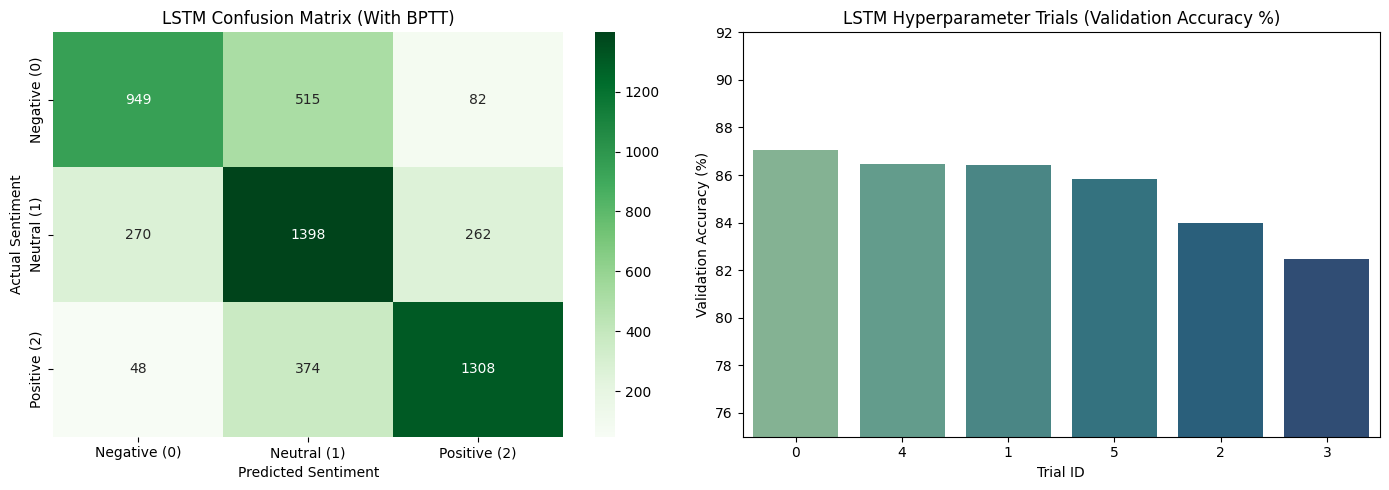


================== DETAILED CLASSIFICATION REPORT ==================
              precision    recall  f1-score   support

Negative (0)       0.75      0.61      0.67      1546
 Neutral (1)       0.61      0.72      0.66      1930
Positive (2)       0.79      0.76      0.77      1730

    accuracy                           0.70      5206
   macro avg       0.72      0.70      0.70      5206
weighted avg       0.71      0.70      0.70      5206



In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

df_trials = pd.DataFrame(trials_data)

# Predict sentiment classes on the unseen test dataset using the best LSTM model
y_pred_probs = best_model.predict(X_test, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

# Create side-by-side plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Confusion Matrix Heatmap (Green theme for LSTM)
cm = confusion_matrix(y_test, y_pred)
class_names = ['Negative (0)', 'Neutral (1)', 'Positive (2)']
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', xticklabels=class_names, yticklabels=class_names, ax=axes[0])
axes[0].set_title('LSTM Confusion Matrix (With BPTT)')
axes[0].set_xlabel('Predicted Sentiment')
axes[0].set_ylabel('Actual Sentiment')

# Plot 2: Hyperparameter Trial Accuracy Bar Chart
sns.barplot(data=df_trials, x='Trial ID', y='Val Accuracy (%)', hue='Trial ID', palette='crest', legend=False, ax=axes[1])
axes[1].set_title('LSTM Hyperparameter Trials (Validation Accuracy %)')
axes[1].set_ylim(75, 92)
axes[1].set_ylabel('Validation Accuracy (%)')
axes[1].set_xlabel('Trial ID')

plt.tight_layout()
plt.show()

# Print detailed Precision, Recall, and F1-Score report for each class
print("\n================== DETAILED CLASSIFICATION REPORT ==================")
print(classification_report(y_test, y_pred, target_names=class_names))